In [291]:
import numpy as np
import cv2 as cv2
import matplotlib.pyplot as plt

In [292]:
img = cv2.imread("H:\\HK1_2026-2027\\ComputerVision\\ComputerVision40\\anhTest.jpg", cv2.IMREAD_GRAYSCALE)

## Một số hàm dùng hỗ trợ

In [293]:
def display(title, img):
    cv2.imshow(title, img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [294]:
def DrawHistogram(img):
    hist, bin_edges = np.histogram(img.flatten(), bins=256, range=[0, 256])

    plt.figure(figsize=(10, 4))
    plt.title("Biểu đồ Histogram")
    plt.xlabel("Mức xám (Intensity)")
    plt.ylabel("Số lượng pixel: ")

    # Dùng bin_edges[:-1] làm tọa độ x, chiều rộng cột là 1
    plt.bar(bin_edges[:-1], hist, width=1.0)

    plt.xlim([0, 256])
    plt.show()

## Xây dựng bảng tra duy nhất cho toàn ảnh

In [295]:
N = img.shape[0] * img.shape[1]
hist, bins = np.histogram(img)

L = 256
c = np.zeros(len(hist))
T = np.zeros(len(hist))

for k in range(0, len(hist)):
    c[k] = (1/N) * np.cumsum(hist)[k]

for k2 in range(0, len(c)):
    T[k2] = np.round((L - 1)*c[k2])

print("Bảng tra T có giá trị như sau")
print(T)

Bảng tra T có giá trị như sau
[224. 241. 248. 250. 252. 253. 253. 254. 254. 255.]


In [296]:
# Tính toán CDF (Đạo hàm của bảng tra)
CDF =  np.zeros(len(hist))

for k in range(0, len(hist)):
    CDF[k] = (L - 1) * (hist[k] / N)

print(CDF)
print("Ta nhận thấy có độc dốc rất lớn")

[224.315       16.55233333   6.9955       2.50466667   1.462
   0.92366667   0.62333333   0.51         0.35416667   0.75933333]
Ta nhận thấy có độc dốc rất lớn


## Xây dựng hàm

In [297]:

def clip_histogram(hist, clip_limit):
    """Cắt và phân phối lại lược đồ.
    hist: mảng (L,) số nguyên. Trả về mảng (L,) đã cắt, tổng không đổi."""

    # Khởi tạo một số biến cần thiết
    Alpha = 120
    e_k = np.zeros(len(hist))

    # Tính toán chỉ số B (đoạn cần cắt)
    B = (N/L) * (1 + (Alpha/100) * (clip_limit - 1))

   # Tính toán e
    for k in range(0, len(e_k)):
        if (hist[k] > B):
            e_k[k] = hist[k] - B
            hist[k] = B

    # Cộng tổng phần dư
    E = np.sum(e_k)

    # Phân phối E đều lại cho toàn bộ L mức h[k] <= h[k] + [E/L]
    for k in range(0, len(hist)):
        hist[k] = hist[k] + E/(len(hist))

    # Phần pixel còn lại
    last = N - np.sum(hist)
    
    hist[0] = hist[0] + last
    return hist

In [298]:
# Test
hist = clip_histogram(hist, 20)
print(hist)
print(np.sum(hist))

[15450 12922  9549  7964  7596  7406  7300  7260  7205  7348]
90000


In [299]:
def build_tile_luts(img, grid=(8, 8), clip_limit=2.0):
    """Trả về mảng (Gy, Gx, L) uint8: bảng tra của từng ô."""

    pass

In [300]:
def clahe(img, grid=(8, 8), clip_limit=2.0):
    """CLAHE đầy đủ. img: (H, W) uint8. Trả về (H, W) uint8."""
    
    pass

## Test


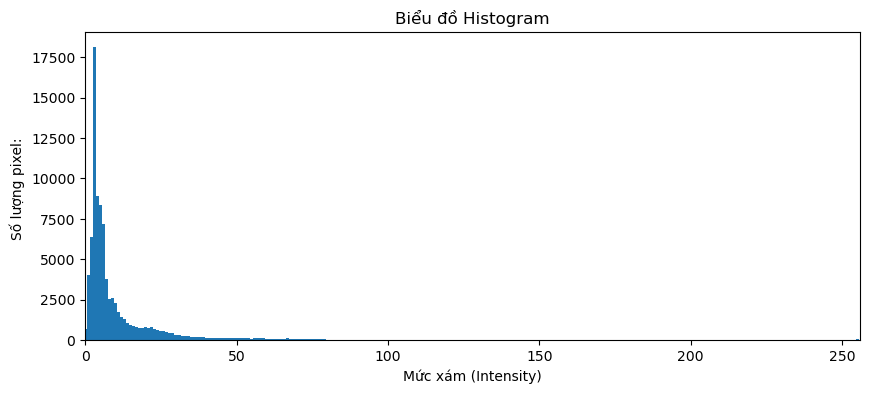

In [301]:
DrawHistogram(img)

## Đối chiếu

In [302]:
# Đây là ô đối chiếu dùng để kiểm tra kết quả in ra của các hàm trên

clahe = cv2.createCLAHE(clipLimit=5)
clahe_img = np.clip(clahe.apply(img) + 25, 0, 255).astype(np.uint8)

display("CLAHE image", clahe_img)

In [303]:
np.histogram(clahe_img)

(array([  602, 44514, 21831,  7457,  4889,  4122,  2666,  1635,  1338,
          946]),
 array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
        229.5, 255. ]))

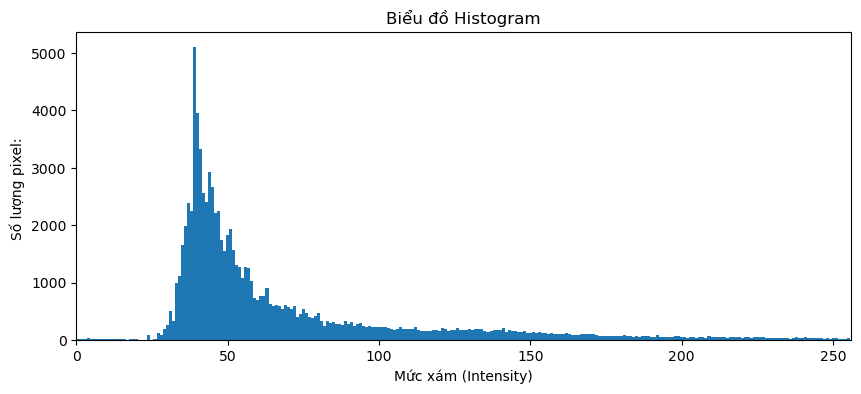

In [304]:
DrawHistogram(clahe_img)